# Solutions · 16 · Model reduction and realisation theory

Worked solutions to the exercises of [notebook 16](../notebooks/16_model_reduction_and_realisation.ipynb). Try each exercise
yourself before reading its solution - the learning happens in the attempt. Solutions are one way to
answer each question; other correct approaches exist.

In [1]:
try:                      # on Google Colab (or anywhere englincontrol is missing): install it from GitHub
    import englincontrol
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/englincontrol"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from englincontrol import systems as sy, linalg as la, identify as idf, response as rs, frequency as fr, mimo, discrete as dc, models
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## Exercise 1

Reduce the quarter-car model (4 states, 2 inputs, 2 outputs) to 2 states by balanced truncation and compare the singular-value plots of the full and reduced models; which mode was dropped, and at what frequency does the reduced model fail?

Hankel singular values: [254.52 239.6   63.25  48.32] -> the two largest carry one mode; the drop to the third is a factor of 3.8


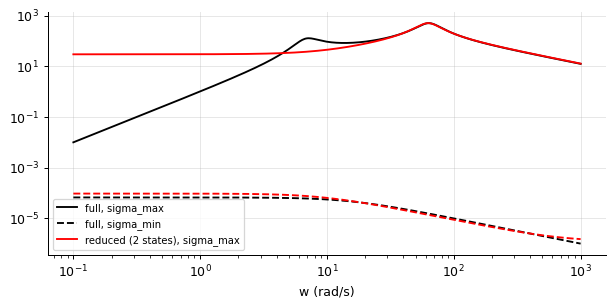

the reduced model keeps the poles [-12.71+61.49j -12.71-61.49j] - the wheel-hop pair - and drops the body-bounce mode near 7 rad/s: it fails below about 20 rad/s


In [2]:
qc = models.quarter_car()["system"]
red = idf.balanced_truncation(qc, 2)
print("Hankel singular values:", np.round(red["hankel_singular_values"], 2), "-> the two largest carry one mode; the drop to the third is a factor of", round(red["hankel_singular_values"][1] / red["hankel_singular_values"][2], 1))
w = np.logspace(-1, 3, 400)
sv_full, sv_red = mimo.sigma(qc, w), mimo.sigma(red["system"], w)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.loglog(w, sv_full[:, 0], "k", label="full, sigma_max"); ax.loglog(w, sv_full[:, 1], "k--", label="full, sigma_min"); ax.loglog(w, sv_red[:, 0], "r", label="reduced (2 states), sigma_max"); ax.loglog(w, sv_red[:, 1], "r--"); ax.legend(fontsize=8); ax.set_xlabel("w (rad/s)"); plt.show()
print(f"the reduced model keeps the poles {np.round(red['system'].poles(), 2)} - the wheel-hop pair - and drops the body-bounce mode near {np.abs(qc.poles()).min():.0f} rad/s: it fails below about 20 rad/s")

Balanced truncation keeps the mode that dominates the input-output *energy*, and with road height as an
input and body acceleration as an output that is the wheel-hop mode at 64 rad/s, not the body bounce one
would have guessed: the reduced model is faithful above 20 rad/s and wrong at the body resonance, exactly
where a ride-comfort controller works. Reduction is relative to the inputs and outputs it is asked to
preserve; scaling them (acceleration in g, road in cm) or choosing frequency-weighted reduction changes the
answer. The Hankel singular values are the honest guide, but the designer must read them against the purpose.

## Exercise 2

Build the Hankel matrix from the motor's noisy impulse response with 10, 30 and 100 Markov parameters and tabulate the first five singular values; how does the gap between the second and third evolve with the record length and the noise?

In [3]:
mot = models.dc_motor()["system"]
Gd = dc.c2d(mot, 0.01)
rng = np.random.default_rng(0)
t, ys = rs.step(Gd, 2.0)
markov_full = np.r_[ys[0], np.diff(ys)]
for n_mk in (10, 30, 100):
    sv = idf.era(markov_full[:n_mk] + 2e-5 * rng.normal(size=n_mk), 2, 0.01)["hankel_singular_values"][:5]
    print(f"{n_mk:3d} Markov parameters: singular values {np.round(sv, 5)}, gap sigma2/sigma3 = {sv[1] / sv[2]:.1f}")

 10 Markov parameters: singular values [2.91e-03 2.70e-04 4.00e-05 1.00e-05], gap sigma2/sigma3 = 7.8
 30 Markov parameters: singular values [1.718e-02 1.890e-03 9.000e-05 6.000e-05 6.000e-05], gap sigma2/sigma3 = 21.2
100 Markov parameters: singular values [0.04681 0.00545 0.00025 0.00025 0.00023], gap sigma2/sigma3 = 21.8


With few Markov parameters the Hankel matrix is small and its noise-induced singular values are comparable
to the true second one: the order is unreadable. As the record grows the true singular values stabilise and
the noise ones shrink (they average down), and the gap between the second and third opens. Order
determination needs a record long enough for that gap to appear - and the gap, not a threshold, is the
criterion.

## Exercise 3

**Implement it yourself:** write the ERA algorithm (block Hankel matrix, SVD, A = S^-1/2 U' H1 V S^-1/2, B and C from the factors) for the DC motor's discrete impulse response and compare the realised transfer function with the ZOH model.

In [4]:
Gd = dc.c2d(models.dc_motor()["system"], 0.01)
t, ys = rs.step(Gd, 1.0)
h = np.r_[ys[0], np.diff(ys)]                                     # Markov parameters h_0, h_1, ...
r = 40; c = len(h) - 1 - r
Hk = np.array([[h[i + j + 1] for j in range(c)] for i in range(r)])
Hk1 = np.array([[h[i + j + 2] for j in range(c)] for i in range(r)])
U, s, Vt = np.linalg.svd(Hk)
n = 2
Ur, Sr, Vr = U[:, :n], np.diag(s[:n]), Vt[:n].T
Sih = np.diag(s[:n] ** -0.5)
A = Sih @ Ur.T @ Hk1 @ Vr @ Sih; B = (np.sqrt(Sr) @ Vr.T)[:, :1]; C = (Ur @ np.sqrt(Sr))[:1, :]
era_sys = sy.ss(A, B, C, h[0], 0.01)
print("ERA by hand: poles", np.round(np.sort(era_sys.poles().real), 6), " ZOH model:", np.round(np.sort(Gd.poles().real), 6))
print("transfer functions:", era_sys.to_tf(), " vs ", Gd.to_tf())

ERA by hand: poles [0.90486  0.980174]  ZOH model: [0.90486  0.980174]
transfer functions: TransferFunction(9.61e-05z + 9.233e-05 / z^2 - 1.885z + 0.8869, dt = 0.01)  vs  TransferFunction(9.61e-05z + 9.233e-05 / z^2 - 1.885z + 0.8869, dt = 0.01)


The Hankel matrix factors as the product of the observability and controllability matrices; its SVD splits
them symmetrically, the shifted Hankel matrix yields A, and the first block column and row give B and C. The
realisation reproduces the ZOH model's poles and transfer function to rounding - Ho and Kalman's 1966
construction, which the library's `era` implements.